# ML Zoomcamp 2026 — Homework 2 (Regression)

Dataset: `car_fuel_efficiency_2026.csv` (pinned 2026 release)

Submit: https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw02

Deadline: Mon 5 Oct 2026, 23:00

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Dataset

Use the 2026 Car Fuel Efficiency dataset and keep only the columns below.
Goal: predict `fuel_efficiency_mpg`.

In [2]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')

cols = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year',
    'fuel_efficiency_mpg',
]
df = df[cols]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


## EDA

Look at `fuel_efficiency_mpg`. Does it have a long tail?

In [3]:
df.fuel_efficiency_mpg.describe()

count    10000.000000
mean        29.997700
std          2.930245
min         19.800000
25%         28.000000
50%         30.000000
75%         31.900000
max         41.200000
Name: fuel_efficiency_mpg, dtype: float64

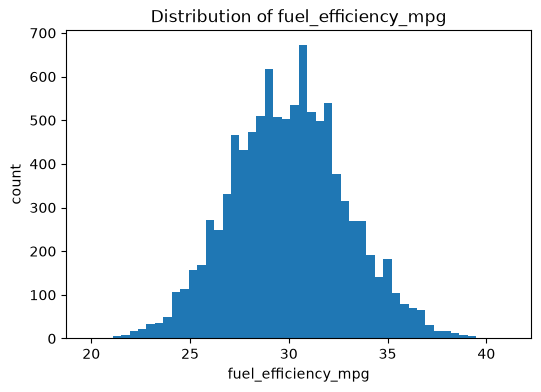

In [4]:
plt.figure(figsize=(6, 4))
plt.hist(df.fuel_efficiency_mpg, bins=50)
plt.xlabel('fuel_efficiency_mpg')
plt.ylabel('count')
plt.title('Distribution of fuel_efficiency_mpg')
plt.show()

The distribution is roughly centered and symmetric (mean ≈ median ≈ 30). **No long tail.**

## Question 1

There's one column with missing values. What is it?

In [5]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

**Answer Q1:** `horsepower`

## Question 2

What's the median (50% percentile) for variable `horsepower`?

In [6]:
df.horsepower.median()

np.float64(254.0)

**Answer Q2:** `254`

## Prepare and split the dataset

Shuffle and split 60% / 20% / 20% as in the lectures.

In [7]:
def split_data(df, seed=42):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]].copy()
    df_val = df.iloc[idx[n_train:n_train + n_val]].copy()
    df_test = df.iloc[idx[n_train + n_val:]].copy()
    return df_train, df_val, df_test

In [8]:
base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']


def prepare_X(df_in, fill_value):
    return df_in[base].fillna(fill_value).values


def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]


def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]


def rmse(y, y_pred):
    return np.sqrt(((y_pred - y) ** 2).mean())

## Question 3

Fill missing values with **0** vs **mean** (mean from training only).
Train linear regression without regularization and compare validation RMSE (round to 3 decimals).

In [9]:
df_train, df_val, df_test = split_data(df, seed=42)

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values

# Option A: fill with 0
X_train = prepare_X(df_train, 0)
w0, w = train_linear_regression(X_train, y_train)
y_pred = w0 + prepare_X(df_val, 0).dot(w)
score_0 = round(rmse(y_val, y_pred), 3)

# Option B: fill with training mean of the missing column
mean_hp = df_train.horsepower.mean()
X_train = prepare_X(df_train, mean_hp)
w0, w = train_linear_regression(X_train, y_train)
y_pred = w0 + prepare_X(df_val, mean_hp).dot(w)
score_mean = round(rmse(y_val, y_pred), 3)

score_0, score_mean

(np.float64(2.205), np.float64(2.202))

**Answer Q3:** With mean (`2.202` < `2.205`)

## Question 4

Fill NAs with 0. Try `r` in `[0, 0.01, 0.1, 1, 5, 10, 100]`.
Pick the `r` with best validation RMSE (round to 4 decimals; smallest `r` on ties).

In [10]:
df_train, df_val, df_test = split_data(df, seed=42)
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values

results = {}
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    X_train = prepare_X(df_train, 0)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    y_pred = w0 + prepare_X(df_val, 0).dot(w)
    results[r] = round(rmse(y_val, y_pred), 4)

results

{0: np.float64(2.2053),
 0.01: np.float64(2.2058),
 0.1: np.float64(2.2241),
 1: np.float64(2.3492),
 5: np.float64(2.4094),
 10: np.float64(2.4195),
 100: np.float64(2.4292)}

**Answer Q4:** `0` (best RMSE `2.2053`)

## Question 5

Try seeds `0..9`. Fill missing with 0, no regularization.
Collect validation RMSE for each seed and report `round(np.std(scores), 3)`.

In [11]:
scores = []
for seed in range(10):
    df_train, df_val, df_test = split_data(df, seed=seed)
    y_train = df_train.fuel_efficiency_mpg.values
    y_val = df_val.fuel_efficiency_mpg.values

    X_train = prepare_X(df_train, 0)
    w0, w = train_linear_regression(X_train, y_train)
    y_pred = w0 + prepare_X(df_val, 0).dot(w)
    scores.append(rmse(y_val, y_pred))

scores, round(float(np.std(scores)), 3)

([np.float64(2.239204143046126),
  np.float64(2.2021128210838845),
  np.float64(2.1634197787530947),
  np.float64(2.2043588768539224),
  np.float64(2.2018800943311554),
  np.float64(2.2457851509085134),
  np.float64(2.2697212079524043),
  np.float64(2.190794599933443),
  np.float64(2.216611201686444),
  np.float64(2.2070365928178957)],
 0.029)

**Answer Q5:** `0.029`

## Question 6

Seed `9`. Combine train + validation. Fill missing with 0. Train with `r=0.001`.
What's the RMSE on the test set?

In [12]:
df_train, df_val, df_test = split_data(df, seed=9)

df_full = pd.concat([df_train, df_val])
y_full = df_full.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

X_full = prepare_X(df_full, 0)
w0, w = train_linear_regression_reg(X_full, y_full, r=0.001)
y_pred = w0 + prepare_X(df_test, 0).dot(w)

round(rmse(y_test, y_pred), 3)

np.float64(2.236)

**Answer Q6:** `2.236`

## Answer sheet

| Q | Answer |
|---|--------|
| 1 | `horsepower` |
| 2 | `254` |
| 3 | With mean |
| 4 | `0` |
| 5 | `0.029` |
| 6 | `2.236` |

Submit: https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw02